# QE012: A Time Crystal on a Noisy Quantum Computer

**Many-body physics in a machine that makes mistakes: building a time crystal, and seeing through the noise.**

A crystal repeats in *space*. A **time crystal** repeats in *time*, and in a stubborn way: we kick a chain of qubits
once per period, but the qubits respond only every *second* period, and they keep doing so even when the kicks are
imperfect. This robustness needs two ingredients working together: interactions between the qubits, and disorder that
stops the system from heating up (*many-body localisation*).

Real quantum computers are noisy, so every signal fades. The question this exercise answers is how we can tell the
physics from the noise.

* **Part A (one exact answer, Euler-style):** simulate an 8-qubit time crystal for 100 periods and report its memory.
* **Part B1:** compare the time crystal with two impostors, free spins and a clean (disorder-free) chain.
* **Part B2:** how imperfect can the kick be before the time crystal melts?
* **Part B3:** add hardware noise, then use the **echo** trick (run the circuit forward, then backward) to separate
  the noise from the physics.
* **Animation:** watch the qubits flip-flop period by period.

### Words used in this notebook

| term | meaning |
|---|---|
| **qubit, ⟨Z⟩** | a two-level system; ⟨Z⟩ = +1 means "up", −1 "down", 0 "no preference" |
| **circuit / gate** | a quantum program; each gate rotates qubits or couples neighbours |
| **period (Floquet cycle)** | one repetition of the same block of gates |
| **kick (X pulse)** | a gate that flips every qubit. A perfect kick (g = 1) flips exactly; g < 1 under-rotates |
| **Ising interaction J** | a coupling that gives each neighbouring pair a phase depending on whether they are aligned |
| **disorder** | random, site-dependent values of J and of local fields h |
| **many-body localisation (MBL)** | strong disorder plus interactions that stop a system from heating up and forgetting its initial state |
| **period doubling** | the response repeats every 2 periods although the drive repeats every 1 |
| **autocorrelation A(t)** | average over qubits of (initial value) × ⟨Z⟩ after t periods; for a time crystal it alternates sign |
| **quasi-energy** | the "energy" of a periodically driven system, defined from the eigenvalues of one period's evolution |
| **π-pairing** | the spectral fingerprint of a time crystal: eigenvalues come in pairs that differ by exactly −1 (a phase of π) |
| **depolarising noise** | with small probability p, a random error (X, Y or Z) hits a qubit |
| **quantum trajectories** | simulating noise by running many copies, each with randomly inserted errors, then averaging |
| **echo** | run the circuit forward t periods, then exactly backward t periods; without noise you return to the start |
| **random seed** | fixes the random draws so every run gives the same numbers |

This notebook needs `numpy`, `pandas` and `matplotlib` (plus Pillow for the animation, which comes with matplotlib).
It runs in about three minutes and writes one GIF animation next to itself.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})
BLUE, ORANGE, GREEN, GRAY, INK, BG = "#2a78d6", "#eb6834", "#1f9e6e", "#8a8984", "#0b0b0b", "#fcfcfb"
noise_rng = np.random.default_rng(12)                            # random seed for the noise

## 1. The circuit

A chain of $L$ qubits. One period is two layers of gates:

1. **Kick:** rotate every qubit about the x-axis by angle $\pi g$, $\;U_X = \prod_j e^{-i\frac{\pi g}{2}X_j}$.
   With $g = 1$ this flips every qubit exactly.
2. **Interactions and fields:** $\;U_Z = \exp\!\big(-i\sum_j J_j Z_j Z_{j+1} - i \sum_j h_j Z_j\big)$, which only adds
   phases.

The state is a list of $2^L$ complex amplitudes. The kick is applied qubit by qubit (each rotation mixes pairs of
amplitudes that differ in one bit), and $U_Z$ is one multiplication by a list of phases. The same code also runs many
copies at once, which we need for the noise trajectories later.

In [2]:
class Chain:
    def __init__(self, L):
        self.L, self.N = L, 2 ** L
        s = np.arange(self.N)
        self.bit = L - 1 - np.arange(L)                          # qubit 0 = leftmost = most significant bit
        self.Z = 1 - 2 * ((s[:, None] >> self.bit) & 1)          # Z[s, j] = +-1
        self.flip = [s ^ (1 << b) for b in self.bit]             # where X on qubit j sends each basis state

    def period(self, g, J, h):
        phases = np.exp(-1j * ((self.Z[:, :-1] * self.Z[:, 1:]) @ J + self.Z @ h))
        def forward(psi, g_=g):
            c, s_ = np.cos(np.pi * g_ / 2), np.sin(np.pi * g_ / 2)
            for q in range(self.L):
                psi = c * psi - 1j * s_ * psi[..., self.flip[q]]
            return psi * phases
        def backward(psi):
            psi = psi * phases.conj()
            c, s_ = np.cos(np.pi * g / 2), np.sin(np.pi * g / 2)
            for q in range(self.L):
                psi = c * psi + 1j * s_ * psi[..., self.flip[q]]
            return psi
        return forward, backward

    def basis_state(self, z, copies=None):
        idx = int(((1 - np.asarray(z)) // 2) @ (2 ** self.bit))
        psi = np.zeros(self.N if copies is None else (copies, self.N), complex)
        psi[..., idx] = 1
        return psi

    def z_values(self, psi):                                     # <Z_j> for every qubit (averaged over copies)
        prob = np.abs(psi) ** 2
        return (prob @ self.Z) if prob.ndim == 1 else (prob @ self.Z).mean(0)

    def y_values(self, psi):                                     # <Y_j>, used by the animation
        psi = np.atleast_2d(psi)
        return np.array([np.mean(np.sum(psi.conj() * (-1j * self.Z[:, q] * psi[:, self.flip[q]]), 1).real)
                         for q in range(self.L)])

## Part A: the memory of a time crystal

Take $L = 8$ qubits with deterministic "disorder" made from fractional parts ($\{x\}$ = $x$ minus its integer part,
$\varphi = (\sqrt5-1)/2$):

$$J_j = -\pi\big(0.4 + 0.2\{j\varphi\}\big), \qquad h_j = \pi\big(2\{j\sqrt2\} - 1\big), \qquad j = 1, 2, \dots$$

for the bonds $j = 1..7$ and the qubits $j = 1..8$. The kick is imperfect, $g = 0.97$. Start with every qubit up.

**Task:** after $t = 100$ periods, compute the expectation value $\langle Z_1\rangle$ of the first qubit and report

$$A = \lfloor 10^6 \cdot \langle Z_1(100)\rangle \rfloor .$$

*Check value:* after 10 periods, $\langle Z_1\rangle = 0.926362\ldots$

In [3]:
frac = lambda x: x - np.floor(x)
j = np.arange(1, 9)
J_A = -np.pi * (0.4 + 0.2 * frac(j[:7] * (np.sqrt(5) - 1) / 2))
h_A = np.pi * (2 * frac(j * np.sqrt(2)) - 1)

chainA = Chain(8)
step, _ = chainA.period(0.97, J_A, h_A)
psi = chainA.basis_state(np.ones(8))
z1 = []
for t in range(1, 101):
    psi = step(psi)
    z1.append(chainA.z_values(psi)[0])
print(f"check, t = 10 : <Z_1> = {z1[9]:.9f}")
print(f"t = 100       : <Z_1> = {z1[99]:.9f}")
A = int(np.floor(1e6 * z1[99]))
print(f"\nANSWER  A = {A}")

check, t = 10 : <Z_1> = 0.926362908
t = 100       : <Z_1> = 0.851947408

ANSWER  A = 851947


**Cross-check with the full one-period matrix.** Build the $256\times256$ Floquet matrix $U_F$ column by column, raise it
to the 100th power, and recompute. Its eigenvalues also show the time-crystal fingerprint, **π-pairing**: for every
eigenvalue $\lambda$ there is another very close to $-\lambda$.

In [4]:
UF = np.column_stack([step(np.eye(256)[:, k].astype(complex)) for k in range(256)])
psi100 = np.linalg.matrix_power(UF, 100) @ chainA.basis_state(np.ones(8))
print(f"matrix-power result: <Z_1(100)> = {chainA.z_values(psi100)[0]:.9f}")

def pi_pairing_gap(U):
    ph = np.sort(np.angle(np.linalg.eigvals(U)))                 # quasi-energy phases in (-pi, pi]
    shifted = np.angle(np.exp(1j * (ph + np.pi)))                # where each partner should sit
    return np.array([np.min(np.abs(np.angle(np.exp(1j * (ph - s))))) for s in shifted])

step_free, _ = chainA.period(0.97, 0 * J_A, h_A)
UF_free = np.column_stack([step_free(np.eye(256)[:, k].astype(complex)) for k in range(256)])
print(f"median distance of a partner from exactly pi away:  time crystal {np.median(pi_pairing_gap(UF)):.2e}"
      f"   free spins {np.median(pi_pairing_gap(UF_free)):.2e}")

matrix-power result: <Z_1(100)> = 0.851947408


median distance of a partner from exactly pi away:  time crystal 1.62e-06   free spins 4.12e-04


In the time crystal every eigenvalue has a partner almost exactly a phase π away, so the dynamics flips sign every
period. For free spins the partners are far from π, and the flipping slowly drifts out of step.

## Part B1: the real thing and two impostors

Now use $L = 10$ qubits, truly random disorder (30 random samples), a random initial up/down pattern, and an imperfect
kick $g = 0.94$. We follow the autocorrelation $A(t)$, the average over qubits of (initial value) × ⟨Z⟩. We plot
$(-1)^t A(t)$, which stays near 1 if the qubits keep flipping in step.

| system | J (interactions) | h (fields) | expected |
|---|---|---|---|
| **time crystal** | random in [−0.6π, −0.4π] | random in [−π, π] | stays near a constant |
| **free spins** | 0 | random in [−π, π] | drifts away: the imperfect kick accumulates |
| **clean chain** | −0.45π everywhere | 0.3 everywhere | heats up: memory drops to a low level |

simulated 90 chains for 100 periods in 2 s


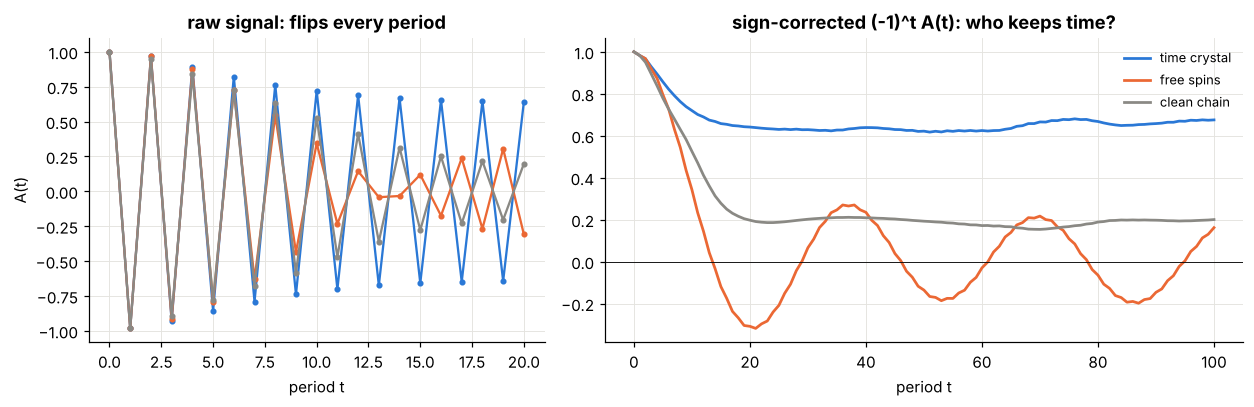

{'time crystal': 0.651, 'free spins': -0.014, 'clean chain': 0.182} <- average over periods 50-100


In [5]:
L, G, T, SAMPLES = 10, 0.94, 100, 30
chain = Chain(L)

def disorder(sample):
    r = np.random.default_rng(1000 + sample)
    return (r.uniform(-0.6 * np.pi, -0.4 * np.pi, L - 1), r.uniform(-np.pi, np.pi, L),
            1 - 2 * r.integers(2, size=L))

def autocorrelation(kind, g=G, T=T, samples=SAMPLES):
    out = np.zeros(T + 1)
    for k in range(samples):
        J, h, z0 = disorder(k)
        if kind == "free spins":
            J = 0 * J
        elif kind == "clean chain":
            J, h = np.full(L - 1, -0.45 * np.pi), np.full(L, 0.3)
        step, _ = chain.period(g, J, h)
        psi = chain.basis_state(z0); out[0] += 1
        for t in range(1, T + 1):
            psi = step(psi); out[t] += chain.z_values(psi) @ z0 / L
    return out / samples

t0 = time.time()
kinds = ["time crystal", "free spins", "clean chain"]
signal = {k: autocorrelation(k) for k in kinds}
print(f"simulated {3 * SAMPLES} chains for {T} periods in {time.time() - t0:.0f} s")

ts = np.arange(T + 1)
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
for k, col in zip(kinds, [BLUE, ORANGE, GRAY]):
    ax[0].plot(ts[:21], signal[k][:21], "o-", ms=3, color=col, label=k)
    ax[1].plot(ts, (-1) ** ts * signal[k], color=col, lw=1.8, label=k)
ax[0].set_title("raw signal: flips every period"); ax[0].set_xlabel("period t"); ax[0].set_ylabel("A(t)")
ax[1].set_title("sign-corrected (-1)^t A(t): who keeps time?"); ax[1].set_xlabel("period t")
ax[1].axhline(0, color=INK, lw=0.6); ax[1].legend(frameon=False, fontsize=8.5)
for a in ax:
    a.grid(color="#e4e3df", lw=0.6)
plt.tight_layout(); plt.show()
print({k: round(float(np.mean((-1) ** ts[50:] * signal[k][50:])), 3) for k in kinds}, "<- average over periods 50-100")

## Part B2: how imperfect can the kick be?

Scan the kick strength $g$ and measure the time-averaged order parameter $\overline{(-1)^t A(t)}$ over periods 50–100.
A time crystal should keep a large value over a whole range of $g$ (a *phase*), while free spins need fine tuning.

scanned in 5 s


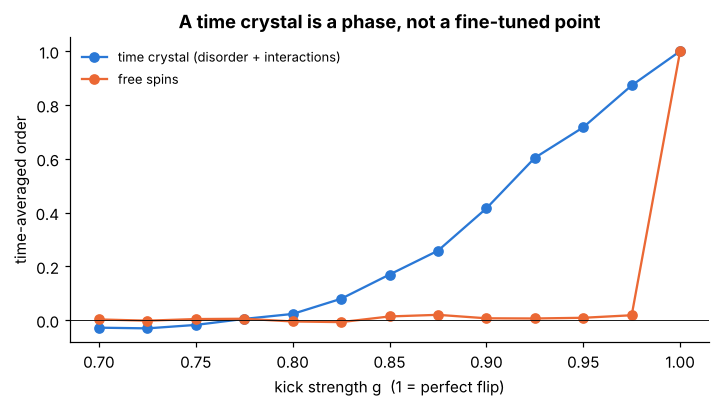

In [6]:
gs = np.round(np.arange(0.70, 1.001, 0.025), 3)
t0 = time.time()
order = {k: [np.mean((-1) ** ts[50:] * autocorrelation(k, g=g, samples=12)[50:]) for g in gs]
         for k in ["time crystal", "free spins"]}
print(f"scanned in {time.time() - t0:.0f} s")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(gs, order["time crystal"], "o-", color=BLUE, label="time crystal (disorder + interactions)")
ax.plot(gs, order["free spins"], "o-", color=ORANGE, label="free spins")
ax.set_xlabel("kick strength g  (1 = perfect flip)"); ax.set_ylabel("time-averaged order")
ax.axhline(0, color=INK, lw=0.6); ax.legend(frameon=False, fontsize=8.5)
ax.set_title("A time crystal is a phase, not a fine-tuned point"); plt.show()

Free spins lose all order as soon as the kick is imperfect: at $g = 0.975$ the order is already zero. The time crystal
keeps most of its order down to $g \approx 0.9$ and only melts around $g \approx 0.85$ for this chain size and disorder
strength. The clean chain in Part B1 does not drop all the way to zero (about 0.2) only because 10 qubits are too few
to heat up completely; longer chains forget more.

## Part B3: noise, and seeing through it with an echo

Real qubits make errors. After every period, each qubit independently suffers a random X, Y or Z error with
probability $p$ (depolarising noise). We simulate this with 96 **quantum trajectories** per disorder sample: copies of
the state with randomly inserted errors, averaged at the end.

Noise makes every signal decay, so a decaying time-crystal signal no longer tells us whether the *physics* decays. The
**echo** answers this. Run $t$ periods forward and then the exact inverse for $t$ periods. Without noise the qubits
return perfectly to the start, so any loss in the echo is due to noise alone. Noise acts on both legs, so the echo
roughly loses the *square* of what one leg loses. That gives a correction:

$$A_\text{corrected}(t) = \frac{A_\text{noisy}(t)}{\sqrt{A_\text{echo}(t)}} .$$

(This normalisation was used in the time-crystal experiment on Google's Sycamore processor.)

In [7]:
def noisy_run(p, copies=96, samples=6, echo_at=(25, 50, 75, 100)):
    A_ = np.zeros(T + 1); E_ = {t: 0.0 for t in echo_at}
    for k in range(samples):
        J, h, z0 = disorder(k)
        fwd, bwd = chain.period(G, J, h)
        psi = chain.basis_state(z0, copies); A_[0] += 1
        def errors(state):
            hit = noise_rng.random((copies, L)) < p
            kind = noise_rng.integers(3, size=(copies, L))
            for q in range(L):
                for e in range(3):                               # e = 0: X, 1: Y, 2: Z
                    m = hit[:, q] & (kind[:, q] == e)
                    if m.any():
                        sub = state[m]
                        if e in (0, 1): sub = sub[:, chain.flip[q]]
                        if e in (1, 2): sub = sub * chain.Z[:, q]
                        state[m] = sub
            return state
        for t in range(1, T + 1):
            psi = errors(fwd(psi))
            A_[t] += chain.z_values(psi) @ z0 / L
            if t in E_:
                back = psi.copy()
                for _ in range(t):
                    back = errors(bwd(back))
                E_[t] += chain.z_values(back) @ z0 / L
    return A_ / samples, {t: v / samples for t, v in E_.items()}

t0 = time.time()
clean_ref = autocorrelation("time crystal", samples=6)           # same 6 disorder samples, no noise
noisy = {p: noisy_run(p) for p in (0.005, 0.01)}
print(f"noisy simulations done in {time.time() - t0:.0f} s")

rows = []
for p, (A_, E_) in noisy.items():
    for t in sorted(E_):
        rows.append({"noise p": p, "period t": t, "noise-free": (-1) ** t * clean_ref[t],
                     "noisy": (-1) ** t * A_[t], "echo": E_[t], "corrected": (-1) ** t * A_[t] / np.sqrt(E_[t])})
echo_table = pd.DataFrame(rows).set_index(["noise p", "period t"]).round(3)
echo_table

noisy simulations done in 74 s


noise-free  noisy   echo  corrected
noise p period t                                     
0.005   25             0.615  0.502  0.607      0.645
        50             0.570  0.392  0.378      0.638
        75             0.652  0.349  0.228      0.731
        100            0.630  0.270  0.144      0.713
0.010   25             0.615  0.407  0.379      0.662
        50             0.570  0.274  0.165      0.674
        75             0.652  0.185  0.075      0.674
        100            0.630  0.121  0.023      0.808

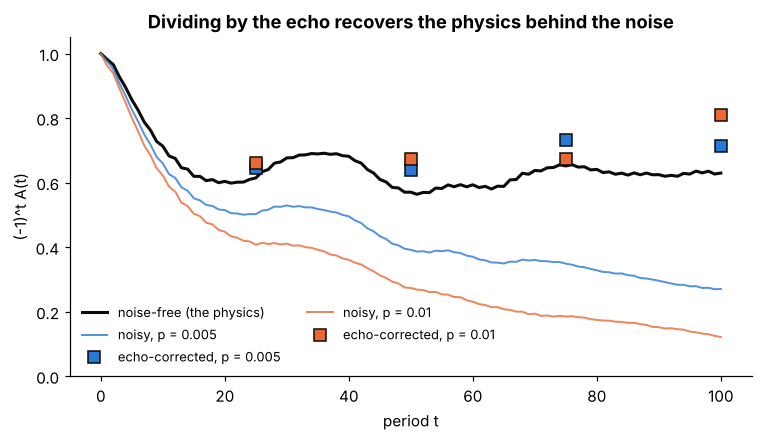

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ts, (-1) ** ts * clean_ref, color=INK, lw=2, label="noise-free (the physics)")
for (p, (A_, E_)), col in zip(noisy.items(), [BLUE, ORANGE]):
    ax.plot(ts, (-1) ** ts * A_, color=col, lw=1.3, alpha=0.8, label=f"noisy, p = {p}")
    tt = np.array(sorted(E_))
    ax.plot(tt, [(-1) ** t * A_[t] / np.sqrt(E_[t]) for t in tt], "s", ms=8, color=col, mec=INK,
            label=f"echo-corrected, p = {p}")
ax.set_xlabel("period t"); ax.set_ylabel("(-1)^t A(t)"); ax.set_ylim(0, 1.05)
ax.legend(frameon=False, fontsize=8.5, ncol=2, loc="lower left")
ax.set_title("Dividing by the echo recovers the physics behind the noise"); plt.show()

The raw signal (thin lines) fades steadily with noise. After dividing by the echo (squares), the values land back near
the noise-free curve. The correction overshoots, by 5% at early times and up to about 30% at the longest times with the strongest noise:
noise during the backward run does not exactly mirror the forward run, and the echo itself becomes small and statistically noisy at long times. This is what the method can
and cannot do: it separates *most* of the noise from the physics, but not all of it.

## Animation: qubits keeping time

Each arrow is one qubit, pointing in the direction of its average spin (up/down = ⟨Z⟩, sideways = ⟨Y⟩). Every period,
the kick rotates all arrows by almost 180°.

* **Top, time crystal:** the pattern flips cleanly every period and repeats every two.
* **Middle, free spins:** the arrows slowly fall out of step.
* **Bottom, time crystal with noise (p = 0.02):** the flipping continues, but the arrows shrink as errors wash out the
  signal.

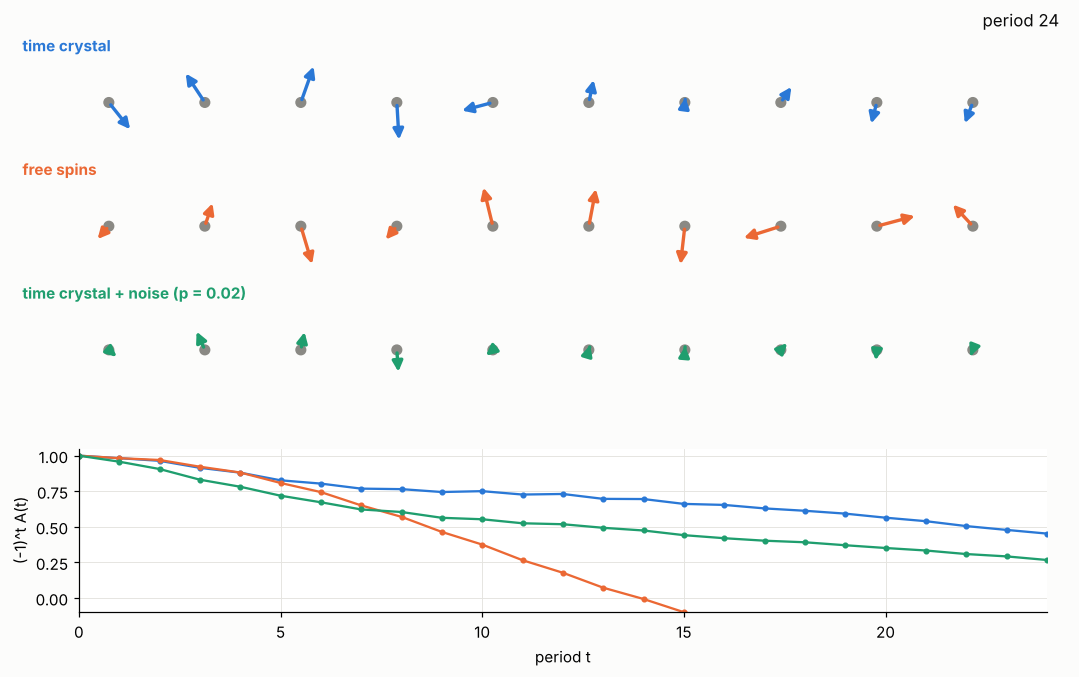

saved qe012_time_crystal.gif (77 s); the final frame is shown above


In [9]:
def time_crystal_animation(filename, periods=24, pulse_frames=6, hold_frames=2, fps=16):
    J, h, z0 = disorder(3)
    systems = {"time crystal": (chain.period(G, J, h)[0], 0.0),
               "free spins": (chain.period(G, 0 * J, h)[0], 0.0),
               "time crystal + noise (p = 0.02)": (chain.period(G, J, h)[0], 0.02)}
    copies = 64
    states = {k: chain.basis_state(z0, copies) for k in systems}
    phases = {k: np.exp(-1j * ((chain.Z[:, :-1] * chain.Z[:, 1:]) @ (0 * J if k == "free spins" else J) + chain.Z @ h))
              for k in systems}
    frames, history = [], {k: [1.0] for k in systems}
    for t in range(periods):
        for f in range(1, pulse_frames + 1):                      # show the kick in slow motion
            snap = {}
            for k in systems:
                partial = states[k]
                c, s_ = np.cos(np.pi * G * f / pulse_frames / 2), np.sin(np.pi * G * f / pulse_frames / 2)
                for q in range(L):
                    partial = c * partial - 1j * s_ * partial[..., chain.flip[q]]
                snap[k] = (chain.y_values(partial), chain.z_values(partial))
            frames.append((t, snap, {k: list(v) for k, v in history.items()}))
        for k, (step, p) in systems.items():                      # complete the period (kick + phases + noise)
            psi = step(states[k])
            if p > 0:
                hit = noise_rng.random((copies, L)) < p; kind = noise_rng.integers(3, size=(copies, L))
                for q in range(L):
                    for e in range(3):
                        m = hit[:, q] & (kind[:, q] == e)
                        if m.any():
                            sub = psi[m]
                            if e in (0, 1): sub = sub[:, chain.flip[q]]
                            if e in (1, 2): sub = sub * chain.Z[:, q]
                            psi[m] = sub
            states[k] = psi
            history[k].append((-1) ** (t + 1) * chain.z_values(psi) @ z0 / L)
        snap = {k: (chain.y_values(states[k]), chain.z_values(states[k])) for k in systems}
        frames += [(t + 1, snap, {k: list(v) for k, v in history.items()})] * hold_frames

    fig = plt.figure(figsize=(10, 6.2), facecolor=BG)
    ax = fig.add_axes([0.02, 0.36, 0.96, 0.6]); ax.set_xlim(-1, L); ax.set_ylim(-0.6, 3 * 1.3 - 0.4); ax.axis("off")
    axs = fig.add_axes([0.08, 0.08, 0.88, 0.24])
    names, cols = list(systems), [BLUE, ORANGE, GREEN]
    rows_y = {k: (2 - i) * 1.3 for i, k in enumerate(names)}

    def draw(i):
        ax.clear(); ax.set_xlim(-1, L); ax.set_ylim(-0.75, 3 * 1.3 - 0.35); ax.axis("off")
        t, snap, hist = frames[i]
        for k, col in zip(names, cols):
            y0 = rows_y[k]; Y, Zv = snap[k]
            ax.text(-0.9, y0 + 0.5, k, fontsize=10, fontweight="bold", color=col, va="bottom")
            for q in range(L):
                ax.add_patch(plt.Circle((q, y0), 0.05, color=GRAY))
                ax.annotate("", xy=(q + 0.45 * Y[q], y0 + 0.45 * Zv[q]), xytext=(q, y0),
                            arrowprops=dict(arrowstyle="-|>", color=col, lw=2.2, mutation_scale=14))
        ax.text(L - 0.1, 3 * 1.3 - 0.5, f"period {t}", ha="right", fontsize=11, color=INK)
        axs.clear()
        for k, col in zip(names, cols):
            axs.plot(range(len(hist[k])), hist[k], "o-", ms=3, color=col, lw=1.5)
        axs.set_xlim(0, periods); axs.set_ylim(-0.1, 1.05); axs.set_xlabel("period t")
        axs.set_ylabel("(-1)^t A(t)"); axs.spines[["top", "right"]].set_visible(False)
        axs.grid(color="#e4e3df", lw=0.6)
        return []

    anim = animation.FuncAnimation(fig, lambda i: draw(min(i, len(frames) - 1)), frames=len(frames) + fps)
    anim.save(filename, writer=animation.PillowWriter(fps=fps), dpi=80, savefig_kwargs={"facecolor": BG})
    draw(len(frames) - 1); plt.show()

t0 = time.time()
time_crystal_animation("qe012_time_crystal.gif")
print(f"saved qe012_time_crystal.gif ({time.time() - t0:.0f} s); the final frame is shown above")

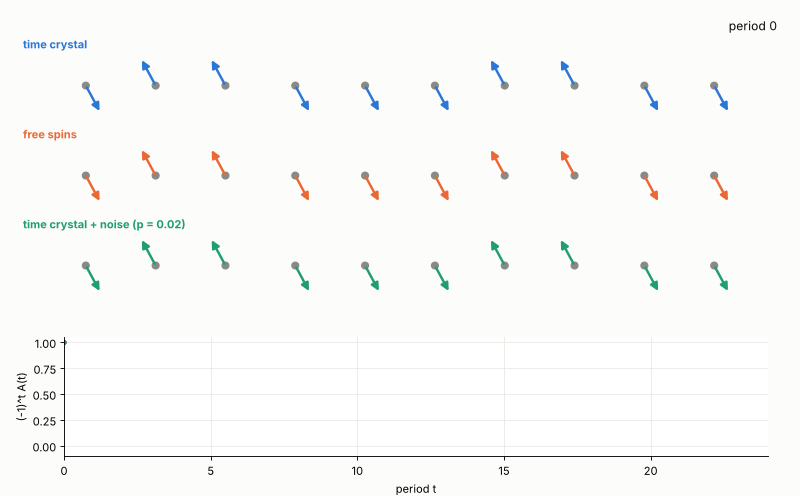

## Conclusions

1. **Exact answer.** The 8-qubit time crystal still remembers its start after 100 imperfect kicks:
   $\langle Z_1(100)\rangle = 0.8519\ldots$, so $A = 851947$, confirmed independently with the full Floquet matrix.
2. **It is a phase of matter.** Disorder plus interactions keep the period-doubled response stable over a range of
   kick strengths. Free spins drift and a clean chain heats up and forgets.
3. **Its fingerprint is in the spectrum.** Floquet eigenvalues come in pairs separated by almost exactly π.
4. **Noise can be partly undone.** On a noisy device the raw signal fades whatever the physics does. Dividing by the
   echo recovers most of the true signal, with a modest over-correction that shows the method's limits.

**Try it yourself:** make the noise act only on some qubits, replace depolarising by amplitude damping (energy loss),
increase L to see π-pairing sharpen, or shrink the disorder until the time crystal melts.

### Further reading

* V. Khemani, A. Lazarides, R. Moessner, S. L. Sondhi, *Phase structure of driven quantum systems*, Phys. Rev. Lett.
  116, 250401 (2016).
* M. Ippoliti, K. Kechedzhi, R. Moessner, S. L. Sondhi, V. Khemani, *Many-body physics in the NISQ era: quantum
  programming a discrete time crystal*, PRX Quantum 2, 030346 (2021).
* X. Mi et al., *Time-crystalline eigenstate order on a quantum processor*, Nature 601, 531 (2022).
* D. V. Else, B. Bauer, C. Nayak, *Floquet time crystals*, Phys. Rev. Lett. 117, 090402 (2016).